#### **STISK2133 Predictive Analytics - Assignment 1**<br>---------------------------------------------------------------------<br>PART A: REGRESSION DIAGNOSTICS & ASSUMPTION TESTING<br>---------------------------------------------------------------------

In [1]:
import pandas as pd
import numpy as np
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# ------------------------------------------------------------
# 1. Load dataset
# ------------------------------------------------------------

df = pd.read_csv("DataTrain_CoolingLoad.csv")

# Select predictors X1 to X8
feature_columns = [f"X{i}" for i in range(1, 9)]

# Select predictors and target variable
data = df[feature_columns + ["Y"]].copy()

# Handle missing and infinite values
data = data.replace([np.inf, -np.inf], np.nan)
data = data.dropna()

# Separate predictors and target variable
X = data[feature_columns]
y = data["Y"]

print("Dataset shape:", X.shape)
print("Target shape:", y.shape)

print("\nMissing values after cleaning:")
print(X.isnull().sum())

Dataset shape: (751, 8)
Target shape: (751,)

Missing values after cleaning:
X1    0
X2    0
X3    0
X4    0
X5    0
X6    0
X7    0
X8    0
dtype: int64


Part A: 1. Multicollinearity Analysis

In [2]:
# Function for calculate the VIF

def calculate_vif(data):
    X_const = add_constant(data, has_constant="add")

    vif_result = pd.DataFrame({
        "Feature": data.columns,
        "VIF": [
            variance_inflation_factor(
                X_const.values, i + 1
            )
            for i in range(data.shape[1])
        ]
    })

    return vif_result.sort_values(
        by="VIF", ascending=False
    ).reset_index(drop=True)

In [3]:
# Part A (1A): Calculate the VIF for all predictors

print("\n========== PART A(a): ORIGINAL VIF ==========")

vif_before = calculate_vif(X)

print(vif_before.to_string(
    index=False,
    float_format="%.3f"
))


========== PART A(a): ORIGINAL VIF ==========
Feature                  VIF
     X2 1000799917193443.500
     X3 1000799917193443.500
     X4 1000799917193443.500
     X1              107.389
     X5               31.481
     X8                1.040
     X7                1.040
     X6                1.000


C:\Users\Admin\AppData\Local\Temp\ipykernel_3168\2190641642.py:9: UserWarning: The design matrix is poorly conditioned (condition number=4.10e+15). VIF calculations may be numerically unstable.
  variance_inflation_factor(
c:\Users\Admin\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
c:\Users\Admin\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
c:\Users\Admin\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OL

In [4]:
# Part A (1B): Identify severe multicollinearity

print("\n========== PART A(b): VIF > 10 ==========")

severe_vif = vif_before[vif_before["VIF"] > 10]

if severe_vif.empty:
    print("No predictors have VIF > 10.")
else:
    print(severe_vif.round(3).to_string(index=False, float_format="%.3f"))


========== PART A(b): VIF > 10 ==========
Feature                  VIF
     X2 1000799917193443.500
     X3 1000799917193443.500
     X4 1000799917193443.500
     X1              107.389
     X5               31.481


Features X1, X2, X3, X4 and X5 have VIF values above 10, indicating serious multicollinearity.

Q: Explain the geometric/physical reason behind multicollinearity in this specific dataset. 

A: Based on the VIF values calculated above, Surface Area(X2), Wall Area(X3) and Roof Area(X4) have similarly high VIF values. This is because they all depend on the size of the building. When the building size increases, these features tend to change together, resulting in multicollinearity. Besides that, Relative Compactness is also strongly related to Surface Area, while Overall Height is another geometric feature of the building. However, their VIF values are lower than those of Surface Area (X2), Wall Area (X3) and Roof Area (X4), indicating that they have multicollinearity, but it is less serious.

**Using Correlation Matrix to indicated the relationship between two features.**

In [5]:
correlation_matrix = X.corr()
print(correlation_matrix.round(3))

       X1     X2     X3     X4     X5     X6     X7     X8
X1  1.000 -0.992 -0.203 -0.871  0.829  0.001 -0.002 -0.001
X2 -0.992  1.000  0.195  0.883 -0.859 -0.001  0.002  0.000
X3 -0.203  0.195  1.000 -0.288  0.279  0.002  0.000  0.004
X4 -0.871  0.883 -0.288  1.000 -0.972 -0.002  0.002 -0.002
X5  0.829 -0.859  0.279 -0.972  1.000  0.002 -0.000  0.003
X6  0.001 -0.001  0.002 -0.002  0.002  1.000  0.004  0.004
X7 -0.002  0.002  0.000  0.002 -0.000  0.004  1.000  0.195
X8 -0.001  0.000  0.004 -0.002  0.003  0.004  0.195  1.000


In [6]:
from sklearn.linear_model import LinearRegression

X_other = X.drop(columns=["X3"])

model = LinearRegression()
model.fit(X_other, X["X3"])

r_squared = model.score(X_other, X["X3"])

print("R-squared:", r_squared)

R-squared: 1.0


In [7]:
# Part A (1C): LASSO FEATURE SELECTION

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LassoCV

y = data["Y"]

# Step 1: Standardize the predictors
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

# Step 2: Apply Lasso Regression with Cross-Validation
lasso = LassoCV(
    cv=5,
    random_state=42,
    max_iter=100000
)

lasso.fit(X_scaled, y)

# Step 3: Display the best Alpha
print("\n========== BEST ALPHA (LAMBDA) ==========")
print("Best Alpha:", lasso.alpha_)

# Step 4: Display the coefficients
lasso_coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": lasso.coef_
})

print("\n========== LASSO COEFFICIENTS ==========")
print(lasso_coefficients.to_string(
    index=False,
    float_format="%.6f"
))

# Step 5: Identify selected predictors
selected_features = X.columns[
    np.abs(lasso.coef_) > 1e-8
]
if len(selected_features) == 0:
    print("No predictors were selected by Lasso.")
else:
    print("Selected Features:", selected_features.tolist())

print("\n========== SELECTED FEATURES ==========")
print(selected_features.tolist())


========== BEST ALPHA (LAMBDA) ==========
Best Alpha: 0.008536324382694504

========== LASSO COEFFICIENTS ==========
Feature  Coefficient
     X1    -5.862633
     X2    -2.180326
     X3    -0.000000
     X4    -3.347344
     X5     8.259570
     X6     0.136467
     X7     1.919873
     X8     0.033771
Selected Features: ['X1', 'X2', 'X4', 'X5', 'X6', 'X7', 'X8']

========== SELECTED FEATURES ==========
['X1', 'X2', 'X4', 'X5', 'X6', 'X7', 'X8']


In [8]:
# Step 6: Create a new dataset using selected predictors
X_selected = X[selected_features]

# Step 7: Recalculate VIF after feature selection
vif_after = calculate_vif(X_selected)

print("\n========== VIF AFTER LASSO ==========")
# Calculate VIF after removing X3
print(vif_after.to_string(
    index=False,
    float_format="%.3f"
))

# Step 8: Compare VIF before and after Lasso
print("\n========== VIF COMPARISON ==========")

vif_comparison = vif_before.merge(
    vif_after,
    on="Feature",
    how="left",
    suffixes=("_Before", "_After")
)

print(vif_comparison.to_string(
    index=False,
    float_format="%.3f"
))


========== VIF AFTER LASSO ==========
Feature     VIF
     X2 113.926
     X1 107.389
     X4  32.846
     X5  31.481
     X8   1.040
     X7   1.040
     X6   1.000

========== VIF COMPARISON ==========
Feature           VIF_Before  VIF_After
     X2 1000799917193443.500    113.926
     X3 1000799917193443.500        NaN
     X4 1000799917193443.500     32.846
     X1              107.389    107.389
     X5               31.481     31.481
     X8                1.040      1.040
     X7                1.040      1.040
     X6                1.000      1.000


Part A - 2. Normality Analysis

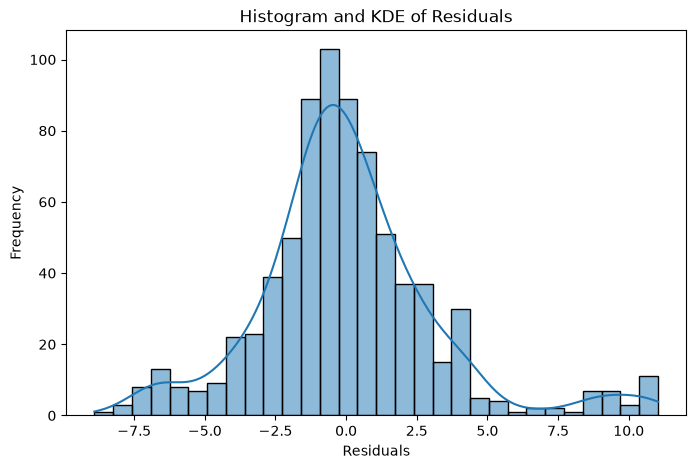

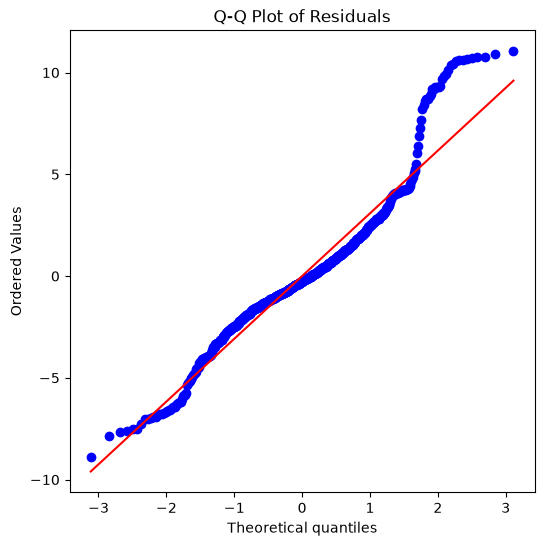

In [9]:
# Part A (2A): Plot a histogram and Q-Q Plot of the model residuals 

from sklearn.linear_model import LinearRegression

# Step 1: Create Linear Regression Model
model = LinearRegression()

# Step 2: Train the model using OLS regression
model.fit(X_selected, y)

# Step 3: Predict Cooling Load
y_pred = model.predict(X_selected)

# Step 4: Calculate Residuals
residuals = y - y_pred

import matplotlib.pyplot as plt
import seaborn as sns

# Plot Histogram and KDE
plt.figure(figsize=(8, 5))

sns.histplot(
    residuals,
    kde=True,
    bins=30
)

plt.title("Histogram and KDE of Residuals")
plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.show()

import scipy.stats as stats

# Plot Q-Q Plot
plt.figure(figsize=(6, 6))

stats.probplot(
    residuals,
    dist="norm",
    plot=plt
)

plt.title("Q-Q Plot of Residuals")
plt.show()

In [10]:
# Part A (2B): Test of normality(Shapiro-Wilk Test)

from scipy.stats import shapiro

# Step 1: Perform Shapiro-Wilk Test
shapiro_stat, p_value = shapiro(residuals)

# Step 2: Display the results
print("\n========== SHAPIRO-WILK TEST ==========")
print("Shapiro-Wilk Statistic:", shapiro_stat)
print("P-value:", p_value)

# Step 3: Interpret the result
if p_value > 0.05:
    print("Residuals are approximately normally distributed.")
else:
    print("Residuals are not normally distributed.")


========== SHAPIRO-WILK TEST ==========
Shapiro-Wilk Statistic: 0.9382796458903127
P-value: 4.2923775451628915e-17
Residuals are not normally distributed.


Null Hypothesis: The residuals is normally distributed.<br>
Alternative Hypothesis: The residuals is not normally distributed.<br>
Since the p-value is smaller than 0.05, null hypothesis is rejected. This indicates that the residuals are not normally distributed.

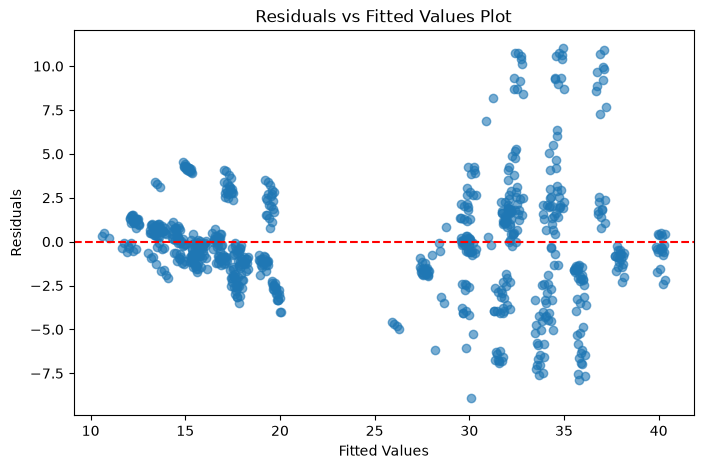

In [11]:
# Plot Residuals vs Fitted Values
plt.figure(figsize=(8, 5))

plt.scatter(y_pred, residuals, alpha=0.6)

plt.axhline(
    y=0,
    color="red",
    linestyle="--"
)

plt.title("Residuals vs Fitted Values Plot")
plt.xlabel("Fitted Values")
plt.ylabel("Residuals")

plt.show()

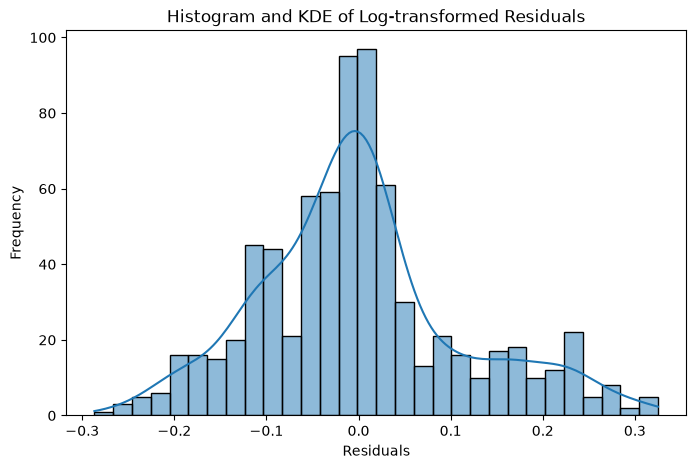

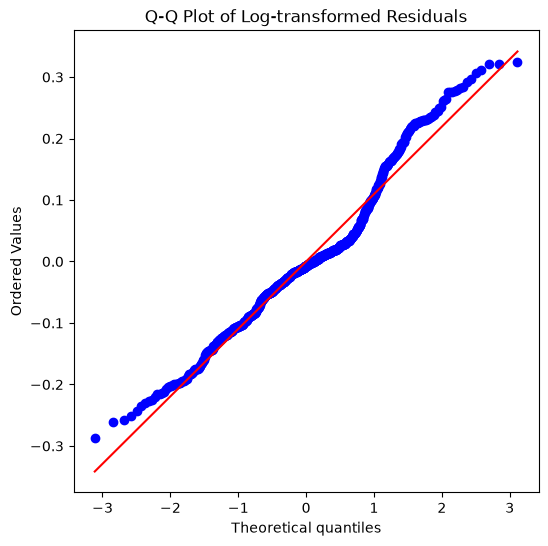


========== SHAPIRO-WILK TEST (LOG) ==========
Shapiro-Wilk Statistic: 0.9677042957225844
P-value: 8.029690238047283e-12
Residuals are not normally distributed.


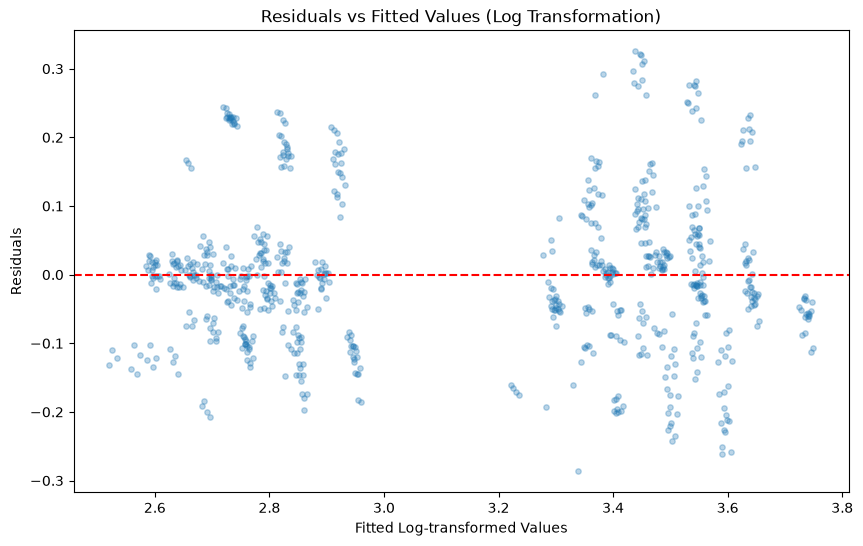

In [12]:
# Part A (2C): LOG TRANSFORMATION OF Y(Fix Heteroscedasticity)

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

from sklearn.linear_model import LinearRegression
from scipy.stats import shapiro


# Step 1: Apply Log Transformation to Y
y_log = np.log(y)


# Step 2: Create Linear Regression Model
model_log = LinearRegression()


# Step 3: Train the model using Log-transformed Y
model_log.fit(X_selected, y_log)


# Step 4: Predict Log-transformed Cooling Load
y_pred_log = model_log.predict(X_selected)


# Step 5: Calculate Residuals
residuals_log = y_log - y_pred_log


# ==========================================
# NORMALITY ANALYSIS
# ==========================================

# Step 6: Plot Histogram and KDE
plt.figure(figsize=(8, 5))
sns.histplot(residuals_log, kde=True, bins=30)

plt.title("Histogram and KDE of Log-transformed Residuals")
plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.show()


# Step 7: Plot Q-Q Plot
plt.figure(figsize=(6, 6))
stats.probplot(residuals_log, dist="norm", plot=plt)

plt.title("Q-Q Plot of Log-transformed Residuals")
plt.show()


# Step 8: Perform Shapiro-Wilk Test
shapiro_stat_log, p_value_log = shapiro(residuals_log)

print("\n========== SHAPIRO-WILK TEST (LOG) ==========")
print("Shapiro-Wilk Statistic:", shapiro_stat_log)
print("P-value:", p_value_log)

if p_value_log > 0.05:
    print("Residuals are approximately normally distributed.")
else:
    print("Residuals are not normally distributed.")


# ==========================================
# HOMOSCEDASTICITY ANALYSIS
# ==========================================

# Step 9: Plot Residuals vs Fitted Values
plt.figure(figsize=(10, 6))

plt.scatter(
    y_pred_log,
    residuals_log,
    alpha=0.3,
    s=15
)

plt.axhline(y=0, color="red", linestyle="--")

plt.title("Residuals vs Fitted Values (Log Transformation)")
plt.xlabel("Fitted Log-transformed Values")
plt.ylabel("Residuals")

plt.show()



========== WLS REGRESSION RESULTS ==========
                            WLS Regression Results                            
Dep. Variable:                      Y   R-squared:                       0.903
Model:                            WLS   Adj. R-squared:                  0.902
Method:                 Least Squares   F-statistic:                     992.7
Date:                Tue, 03 Nov 2026   Prob (F-statistic):               0.00
Time:                        00:38:18   Log-Likelihood:                -1844.1
No. Observations:                 751   AIC:                             3704.
Df Residuals:                     743   BIC:                             3741.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const 

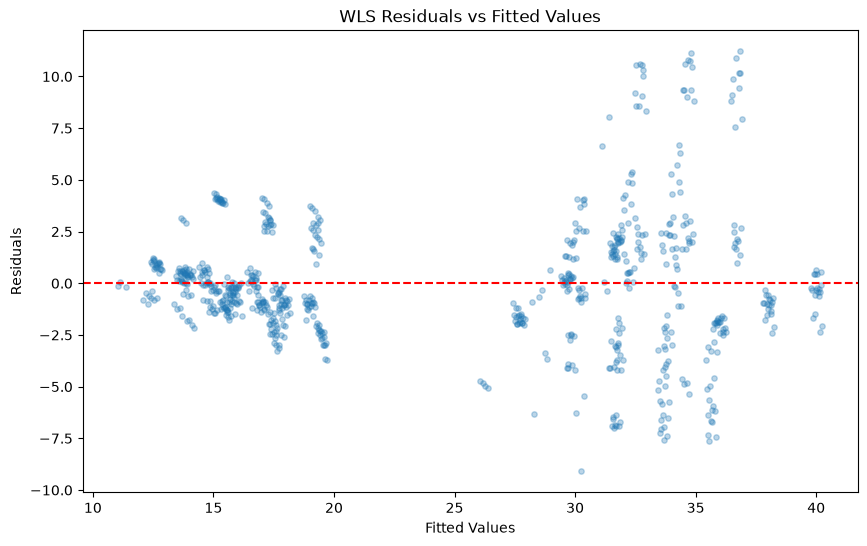

In [13]:
# Part A (2C): WEIGHTED LEAST SQUARES (WLS)(Fix Heteroscedasticity)

import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

# Step 1: Add constant (intercept)
X_selected_const = sm.add_constant(X_selected)

# Step 2: Create and fit OLS Model
model_ols = sm.OLS(y, X_selected_const).fit()

# Step 3: Calculate squared residuals
squared_residuals = model_ols.resid ** 2

# Step 4: Estimate the error variance
variance_model = sm.OLS(
    squared_residuals,
    model_ols.fittedvalues.to_frame(name="Fitted")
).fit()

# Step 5: Calculate weights
estimated_variance = variance_model.predict(
    model_ols.fittedvalues.to_frame(name="Fitted")
)

estimated_variance = np.maximum(estimated_variance, 1e-6)

weights = 1 / estimated_variance

# Step 6: Create and fit WLS Model
model_wls = sm.WLS(
    y,
    X_selected_const,
    weights=weights
).fit()

# Step 7: Display WLS Results
print("\n========== WLS REGRESSION RESULTS ==========")
print(model_wls.summary())

# Step 8: Calculate Fitted Values and Residuals
y_pred_wls = model_wls.fittedvalues
residuals_wls = model_wls.resid

# Step 9: Residuals vs Fitted Values Plot
plt.figure(figsize=(10, 6))
plt.scatter(y_pred_wls, residuals_wls, alpha=0.3, s=15)
plt.axhline(y=0, color="red", linestyle="--")
plt.title("WLS Residuals vs Fitted Values")
plt.xlabel("Fitted Values")
plt.ylabel("Residuals")
plt.show()

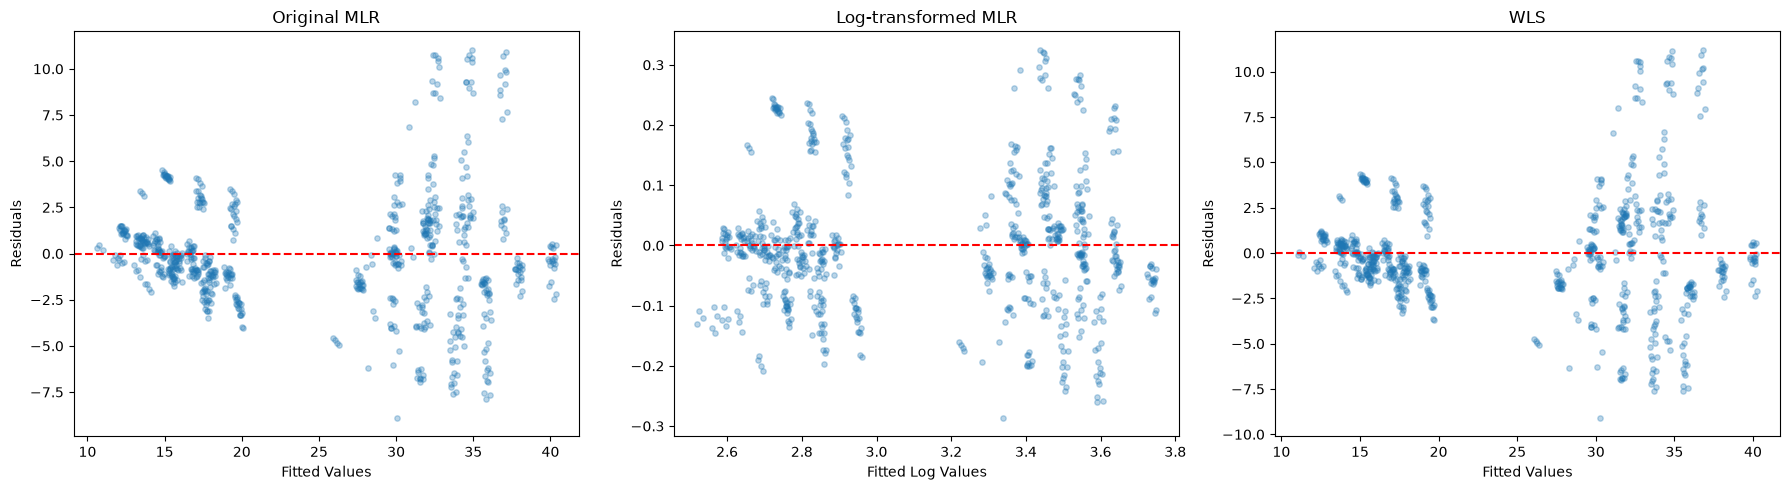

In [14]:
# Compare Original, Log-transformed and WLS Residual Plots

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Original MLR
axes[0].scatter(y_pred, residuals, alpha=0.3, s=15)
axes[0].axhline(y=0, color="red", linestyle="--")
axes[0].set_title("Original MLR")
axes[0].set_xlabel("Fitted Values")
axes[0].set_ylabel("Residuals")

# Log-transformed MLR
axes[1].scatter(y_pred_log, residuals_log, alpha=0.3, s=15)
axes[1].axhline(y=0, color="red", linestyle="--")
axes[1].set_title("Log-transformed MLR")
axes[1].set_xlabel("Fitted Log Values")
axes[1].set_ylabel("Residuals")

# WLS
axes[2].scatter(y_pred_wls, residuals_wls, alpha=0.3, s=15)
axes[2].axhline(y=0, color="red", linestyle="--")
axes[2].set_title("WLS")
axes[2].set_xlabel("Fitted Values")
axes[2].set_ylabel("Residuals")

plt.tight_layout()
plt.show()

In [15]:
# Part A (2C): robust standard errors

import statsmodels.api as sm

# Step 1: Add constant (intercept)
X_selected_const = sm.add_constant(X_selected)

# Step 2: Create and fit OLS Model
model_ols = sm.OLS(y, X_selected_const).fit()

# Step 3: Calculate Robust Standard Errors (HC3)
model_robust = model_ols.get_robustcov_results(cov_type="HC3")

# Step 4: Display Regression Results
print(model_robust.summary())

                            OLS Regression Results                            
Dep. Variable:                      Y   R-squared:                       0.889
Model:                            OLS   Adj. R-squared:                  0.888
Method:                 Least Squares   F-statistic:                     1872.
Date:                Tue, 03 Nov 2026   Prob (F-statistic):               0.00
Time:                        00:38:20   Log-Likelihood:                -1932.5
No. Observations:                 751   AIC:                             3881.
Df Residuals:                     743   BIC:                             3918.
Df Model:                           7                                         
Covariance Type:                  HC3                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         97.2978     13.357      7.284      0.0

The Shapiro-Wilk test, Q-Q plot and histogram indicate that the residuals are not normally distributed. Log Transformation improved normality but did not completely satisfy the normality assumption. Both Log Transformation and Weighted Least Squares (WLS) were considered, but they did not eliminate heteroscedasticity. Therefore, HC3 robust standard errors are recommended to adjust the standard errors and provide more reliable statistical inference in the presence of heteroscedasticity.

#### -------------------------------------<br>PART B: MODEL DEVELOPMENT<br>-------------------------------------

Part B - 1. Data Preprocessing & Exploratory Data Analysis

In [16]:
# Part B (1A):  Missing Value Handling

original_data = pd.read_csv("DataTrain_CoolingLoad.csv")

# Step 1: Check original missing values
print("Missing Values:")
print(original_data.isnull().sum())

# Step 2: Check infinite values
print("\nInfinite Values:")
print(np.isinf(original_data.select_dtypes(include=np.number)).sum())

# Step 3: Count rows containing missing values
missing_rows = original_data.isnull().any(axis=1).sum()

# Step 4: Count rows containing infinite values
infinite_rows = np.isinf(
    original_data.select_dtypes(include=np.number)
).any(axis=1).sum()

# Step 5: Count rows containing either missing or infinite values
invalid_rows = (
    original_data.isnull().any(axis=1) |
    np.isinf(original_data.select_dtypes(include=np.number)).any(axis=1)
).sum()

print("\nTotal Original Rows:", len(original_data))
print("Rows with Missing Values:", missing_rows)
print("Rows with Infinite Values:", infinite_rows)
print("Rows with Missing or Infinite Values:", invalid_rows)
print("Rows After Cleaning:", len(original_data) - invalid_rows)

Missing Values:
X1    1
X2    5
X3    6
X4    3
X5    0
X6    1
X7    1
X8    0
Y     0
dtype: int64

Infinite Values:
X1    0
X2    0
X3    0
X4    0
X5    0
X6    0
X7    0
X8    0
Y     0
dtype: int64

Total Original Rows: 768
Rows with Missing Values: 17
Rows with Infinite Values: 0
Rows with Missing or Infinite Values: 17
Rows After Cleaning: 751


The dataset was checked for missing values. After data cleaning, no missing values were found in the dataset. Therefore, no further missing value handling was required.

In [17]:
# Part B (1A): Summary Statistics
print("Summary Statistics:")
data.describe()

Summary Statistics:


,X1,X2,X3,X4,X5,X6,X7,X8,Y
count,751.000000,751.000000,751.00000,751.000000,751.000000,751.000000,751.000000,751.000000,751.000000
mean,0.764967,671.123835,317.88016,176.621838,5.247670,3.499334,0.236152,2.837550,24.603928
std,0.106186,88.286711,43.33587,45.212765,1.751165,1.121754,0.132795,1.543235,9.519375
min,0.620000,514.500000,245.00000,110.250000,3.500000,2.000000,0.000000,0.000000,10.900000
25%,0.690000,588.000000,294.00000,134.750000,3.500000,2.000000,0.100000,2.000000,15.610000
50%,0.740000,686.000000,318.50000,220.500000,3.500000,3.000000,0.250000,3.000000,22.090000
75%,0.860000,735.000000,343.00000,220.500000,7.000000,5.000000,0.400000,4.000000,33.095000
max,0.980000,808.500000,416.50000,220.500000,7.000000,5.000000,0.400000,5.000000,48.030000


The summary statistics show that the dataset contains 751 observations, 8 independent variables and 1 dependent variable (Y). The mean Cooling Load (Y) is 24.60, with a standard deviation of 9.52. The minimum and maximum values of Y are 10.90 and 48.03, respectively. The features have different ranges and scales, indicating differences in their numerical distributions.

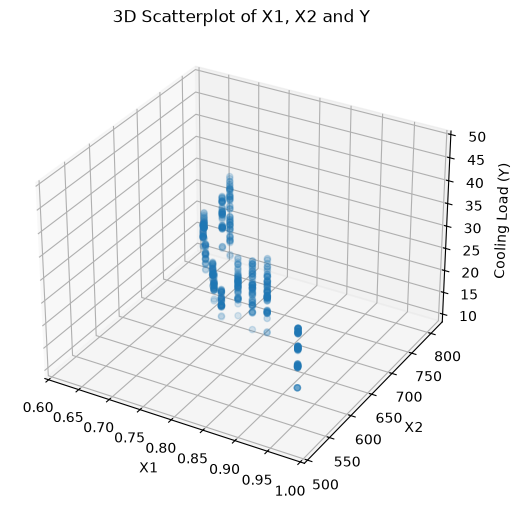

In [18]:
# Part B (1A): 3D scatterplots

# 3D Scatterplot 1: X1, X2 and Y
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(data["X1"], data["X2"], data["Y"], alpha=0.5)

ax.set_xlabel("X1")
ax.set_ylabel("X2")
ax.set_zlabel("Cooling Load (Y)")
ax.set_title("3D Scatterplot of X1, X2 and Y")

plt.show()

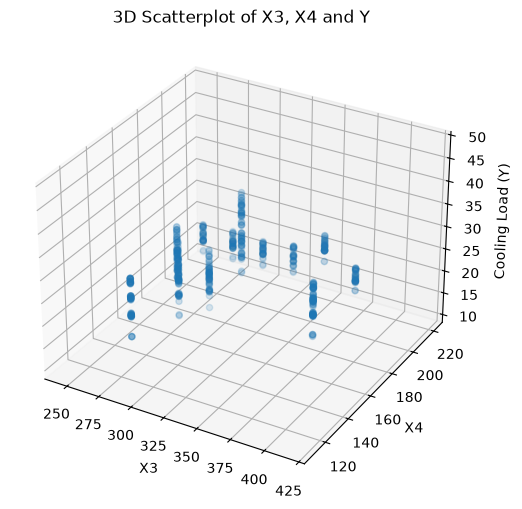

In [19]:
# 3D Scatterplot 2: X3, X4 and Y

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(data["X3"], data["X4"], data["Y"], alpha=0.5)

ax.set_xlabel("X3")
ax.set_ylabel("X4")
ax.set_zlabel("Cooling Load (Y)")
ax.set_title("3D Scatterplot of X3, X4 and Y")

plt.show()

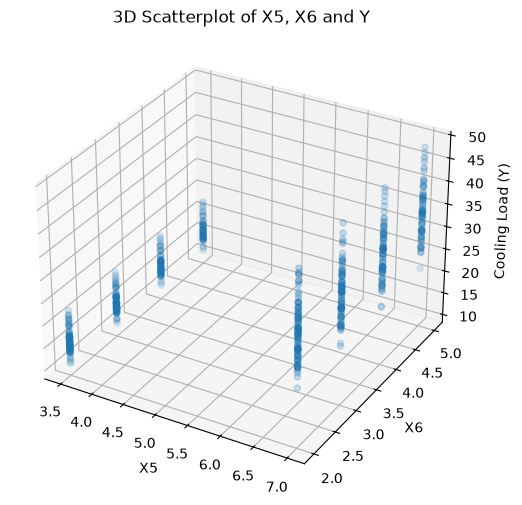

In [20]:
# 3D Scatterplot 3: X5, X6 and Y

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(data["X5"], data["X6"], data["Y"], alpha=0.5)

ax.set_xlabel("X5")
ax.set_ylabel("X6")
ax.set_zlabel("Cooling Load (Y)")
ax.set_title("3D Scatterplot of X5, X6 and Y")

plt.show()

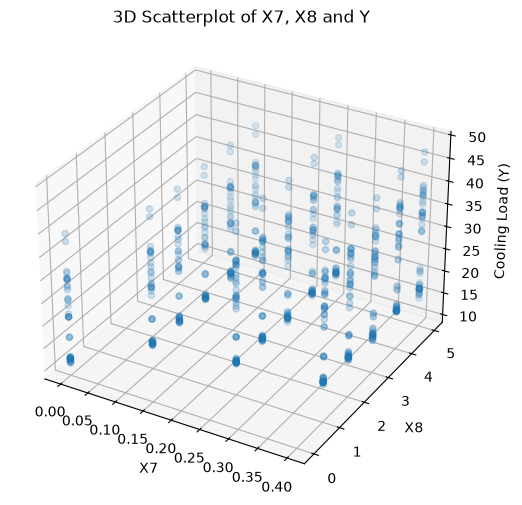

In [21]:
# 3D Scatterplot 4: X7, X8 and Y

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(data["X7"], data["X8"], data["Y"], alpha=0.5)

ax.set_xlabel("X7")
ax.set_ylabel("X8")
ax.set_zlabel("Cooling Load (Y)")
ax.set_title("3D Scatterplot of X7, X8 and Y")

plt.show()

In [22]:
# Part B (1A): Correlation Heatmap

import seaborn as sns
import matplotlib.pyplot as plt

correlation_matrix = data.corr()

correlation_matrix

,X1,X2,X3,X4,X5,X6,X7,X8,Y
X1,1.000000,-0.991956,-0.202571,-0.871413,0.828874,0.000643,-0.002208,-0.001172,0.636107
X2,-0.991956,1.000000,0.195475,0.882667,-0.858808,-0.000760,0.001909,0.000221,-0.674632
X3,-0.202571,0.195475,1.000000,-0.288393,0.279455,0.001671,0.000209,0.003865,0.424202
X4,-0.871413,0.882667,-0.288393,1.000000,-0.972422,-0.001543,0.001764,-0.001636,-0.861971
X5,0.828874,-0.858808,0.279455,-0.972422,1.000000,0.001781,-0.000139,0.003313,0.897329
X6,0.000643,-0.000760,0.001671,-0.001543,0.001781,1.000000,0.004413,0.003788,0.018014
X7,-0.002208,0.001909,0.000209,0.001764,-0.000139,0.004413,1.000000,0.194927,0.203649
X8,-0.001172,0.000221,0.003865,-0.001636,0.003313,0.003788,0.194927,1.000000,0.047965
Y,0.636107,-0.674632,0.424202,-0.861971,0.897329,0.018014,0.203649,0.047965,1.000000


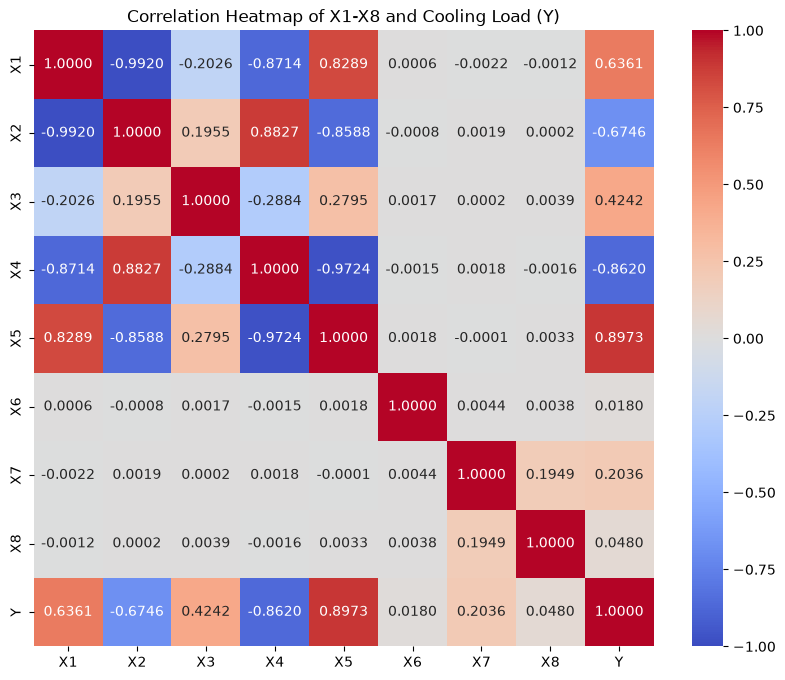

In [23]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".4f",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Correlation Heatmap of X1-X8 and Cooling Load (Y)")
plt.show()

In [24]:
# Part B (1B): Split the dataset into an 80% training set and a 20% test set 

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (600, 8)
X_test shape: (151, 8)
y_train shape: (600,)
y_test shape: (151,)


Part B - 2. Multiple Linear Regression (MLR- Baseline Model)

In [25]:
# Part B (2A): Fit a Multiple Linear Regression model

from sklearn.linear_model import LinearRegression

mlr_model = LinearRegression()

mlr_model.fit(X_train, y_train)

print("Intercept:", mlr_model.intercept_)

print("\nCoefficients:")
for feature, coefficient in zip(X_train.columns, mlr_model.coef_):
    print(f"{feature}: {coefficient}")

Intercept: 95.79604093619446

Coefficients:
X1: -71.24667385337418
X2: -0.06451273244088801
X3: 0.021425445322695802
X4: -0.042969088912737305
X5: 4.464948978378445
X6: 0.10930818828673129
X7: 14.622791104143452
X8: 0.057986291259713774


In [26]:
# Part B (2B): Evaluate model performance on both training and testing datasets

y_train_pred = mlr_model.predict(X_train)
y_test_pred = mlr_model.predict(X_test)

from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Evaluate Training Performance
train_r2 = r2_score(y_train, y_train_pred)

n_train = len(y_train)
p = X_train.shape[1]

train_adjusted_r2 = 1 - (1 - train_r2) * (n_train - 1) / (n_train - p - 1)

train_mae = mean_absolute_error(y_train, y_train_pred)

train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))

# Evaluate Testing Performance
test_r2 = r2_score(y_test, y_test_pred)

n_test = len(y_test)

test_adjusted_r2 = 1 - (1 - test_r2) * (n_test - 1) / (n_test - p - 1)

test_mae = mean_absolute_error(y_test, y_test_pred)

test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))

print("Training Performance")
print("R2:", train_r2)
print("Adjusted R2:", train_adjusted_r2)
print("MAE:", train_mae)
print("RMSE:", train_rmse)

print("\nTesting Performance")
print("R2:", test_r2)
print("Adjusted R2:", test_adjusted_r2)
print("MAE:", test_mae)
print("RMSE:", test_rmse)

Training Performance
R2: 0.878953862361969
Adjusted R2: 0.8773153359641616
MAE: 2.358442863779034
RMSE: 3.314202915391678

Testing Performance
R2: 0.9276362130768027
Adjusted R2: 0.923559380010707
MAE: 1.792963441091233
RMSE: 2.539159101191996


Regression evaluation metrics were used to evaluate the MLR model. Both R-Squared and Adjusted R-Squared value were higher on the testing dataset compared to training dataset. Besides that, MAE and RMSE values were also lower on testing dataset compared to training dataset. Since higher R-Squared and Adjusted R-Squared values indicate better model performance, while lower MAE and RMSE values indicate better prediction accuracy, these results suggest that the model performed well on unseen data. The testing performance is better than training performance, indicating no obvious signs for overfitting.

Part B - 3. Polynomial Regression

In [27]:
# Part B (3A): Fit Polynomial Regression models

from sklearn.preprocessing import PolynomialFeatures

# Polynomial Regression models of Degree 2
poly2 = PolynomialFeatures(degree=2, include_bias=False)

# Combining the 8 features into pairwise interaction terms
X_train_poly2 = poly2.fit_transform(X_train)
X_test_poly2 = poly2.transform(X_test)

print("Original features:", X_train.shape[1])
print("Degree 2 features:", X_train_poly2.shape[1])

Original features: 8
Degree 2 features: 44


In [28]:
poly2_model = LinearRegression()
poly2_model.fit(X_train_poly2, y_train)

y_train_poly2_pred = poly2_model.predict(X_train_poly2)
y_test_poly2_pred = poly2_model.predict(X_test_poly2)

In [29]:
# Training Performance
train_poly2_r2 = r2_score(y_train, y_train_poly2_pred)

n_train = len(y_train)
p = X_train_poly2.shape[1]

train_poly2_adjusted_r2 = 1 - (1 - train_poly2_r2) * (n_train - 1) / (n_train - p - 1)

train_poly2_mae = mean_absolute_error(y_train, y_train_poly2_pred)
train_poly2_rmse = np.sqrt(mean_squared_error(y_train, y_train_poly2_pred))


# Testing Performance
test_poly2_r2 = r2_score(y_test, y_test_poly2_pred)

n_test = len(y_test)

test_poly2_adjusted_r2 = 1 - (1 - test_poly2_r2) * (n_test - 1) / (n_test - p - 1)

test_poly2_mae = mean_absolute_error(y_test, y_test_poly2_pred)
test_poly2_rmse = np.sqrt(mean_squared_error(y_test, y_test_poly2_pred))


print("Degree 2 Polynomial Regression")
print("\nTraining Performance:")
print("R2:", train_poly2_r2)
print("Adjusted R2:", train_poly2_adjusted_r2)
print("MAE:", train_poly2_mae)
print("RMSE:", train_poly2_rmse)

print("\nTesting Performance:")
print("R2:", test_poly2_r2)
print("Adjusted R2:", test_poly2_adjusted_r2)
print("MAE:", test_poly2_mae)
print("RMSE:", test_poly2_rmse)

Degree 2 Polynomial Regression

Training Performance:
R2: 0.9227065668878698
Adjusted R2: 0.9165787992177189
MAE: 2.013229620677126
RMSE: 2.648347229332625

Testing Performance:
R2: 0.9272716409392895
Adjusted R2: 0.8970825107631455
MAE: 1.930003076711776
RMSE: 2.5455472663902405


Based on the Degree 2 Polynomial Regression, the R-squared value on the testing dataset is slightly higher than that of the training dataset, while the Adjusted R-squared value is lower. Meanwhile, the MAE and RMSE values are also lower on the testing dataset compared to the training dataset. Although Adjusted R-squared value shows lower performance on the testing dataset, the model also shows no obvious signs of overfitting.

In [30]:
# Polynomial Regression models of Degree 3
poly3 = PolynomialFeatures(degree=3, include_bias=False)

X_train_poly3 = poly3.fit_transform(X_train)
X_test_poly3 = poly3.transform(X_test)

print("Original features:", X_train.shape[1])
print("Degree 3 features:", X_train_poly3.shape[1])

Original features: 8
Degree 3 features: 164


In [31]:
poly3_model = LinearRegression()
poly3_model.fit(X_train_poly3, y_train)

y_train_poly3_pred = poly3_model.predict(X_train_poly3)
y_test_poly3_pred = poly3_model.predict(X_test_poly3)

In [32]:
# Training Performance
train_poly3_r2 = r2_score(y_train, y_train_poly3_pred)

n_train = len(y_train)
p = X_train_poly3.shape[1]

train_poly3_adjusted_r2 = 1 - (1 - train_poly3_r2) * (n_train - 1) / (n_train - p - 1)

train_poly3_mae = mean_absolute_error(y_train, y_train_poly3_pred)
train_poly3_rmse = np.sqrt(mean_squared_error(y_train, y_train_poly3_pred))


# Testing Performance
test_poly3_r2 = r2_score(y_test, y_test_poly3_pred)

n_test = len(y_test)

if n_test > p + 1:
    test_poly3_adjusted_r2 = 1 - (1 - test_poly3_r2) * (n_test - 1) / (n_test - p - 1)
else:
    test_poly3_adjusted_r2 = None

test_poly3_mae = mean_absolute_error(y_test, y_test_poly3_pred)
test_poly3_rmse = np.sqrt(mean_squared_error(y_test, y_test_poly3_pred))


print("Degree 3 Polynomial Regression")
print("\nTraining Performance:")
print("R2:", train_poly3_r2)
print("Adjusted R2:", train_poly3_adjusted_r2)
print("MAE:", train_poly3_mae)
print("RMSE:", train_poly3_rmse)

print("\nTesting Performance:")
print("R2:", test_poly3_r2)
print("Adjusted R2:", test_poly3_adjusted_r2)
print("MAE:", test_poly3_mae)
print("RMSE:", test_poly3_rmse)

Degree 3 Polynomial Regression

Training Performance:
R2: 0.9203191248434663
Adjusted R2: 0.8902785190373249
MAE: 2.0358880983073484
RMSE: 2.688937293358417

Testing Performance:
R2: 0.9256825616545502
Adjusted R2: None
MAE: 1.9354208427239827
RMSE: 2.5732064827313663


The results of Degree 3 Polynomial Regression show no obvious signs of model overfitting. The R-squared value on the testing dataset is slightly higher than that of the training dataset. Meanwhile, the MAE and RMSE values are lower on the testing dataset compared to the training dataset. However, the Adjusted R-squared value for the testing dataset cannot be calculated because the number of features exceeds the number of testing observations.


Based on the regression evaluation metrics, higher R-squared and Adjusted R-squared values indicate better model performance, while lower MAE and RMSE values indicate better prediction accuracy.

Degree 2 achieves slightly better testing performance, with a higher R-squared value (0.9273), lower MAE (1.9300) and lower RMSE (2.5455) compared to Degree 3, which has an R-squared value of 0.9257, MAE of 1.9354 and RMSE of 2.5732.

Furthermore, Degree 2 generates only 44 features, while Degree 3 generates 164 features, resulting in higher model complexity for Degree 3. The Adjusted R-squared for Degree 3 testing performance cannot be calculated using the standard formula because the number of testing observations is smaller than the number of features.

Based on the comparison, Degree 2 Polynomial Regression provides a better balance between predictive power and overfitting risk. Therefore, Degree 2 is preferred because it provides slightly better predictive performance with lower model complexity and potentially lower overfitting risk.


Part B - 4. Multiple Linear Regression with Principal Component Analysis (MLR + PCA Model)

In [33]:
# Part B (4A): Standardise the numerical predictors using Z-score feature scaling

from sklearn.preprocessing import StandardScaler

# Standardisation
scaler_pca = StandardScaler()

X_train_scaled = scaler_pca.fit_transform(X_train)
X_test_scaled = scaler_pca.transform(X_test)

# Check the results
print("Training data mean:")
print(X_train_scaled.mean(axis=0))

print("\nTraining data standard deviation:")
print(X_train_scaled.std(axis=0))

Training data mean:
[-9.41469125e-16  1.22864681e-16  6.35787719e-16 -2.01320442e-16
 -7.25345709e-17 -2.59052039e-17 -2.42768768e-16 -4.73695157e-17]

Training data standard deviation:
[1. 1. 1. 1. 1. 1. 1. 1.]


Standardisation is a mandatory prerequisite for PCA because PCA is sensitive to the variance of the features. PC1 captures the maximum variance, while PC2 captures the highest remaining variance. Therefore, different scales among variables can affect the PCA results. Standardisation transforms the values of variables to a common scale by giving each feature a mean of 0 and a standard deviation of 1. This ensures that all features contribute more fairly to PCA and prevents features with larger numerical values from dominating the results.

In [34]:
# Part B (4B): Perform Principal Component Analysis (PCA)

from sklearn.decomposition import PCA

pca = PCA()

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

# Explained variance ratio
explained_variance = pca.explained_variance_ratio_

print("Explained Variance Ratio:")
print(explained_variance)

# Cumulative explained variance
cumulative_variance = np.cumsum(explained_variance)

print("\nCumulative Explained Variance:")
print(cumulative_variance)

Explained Variance Ratio:
[0.46372048 0.15456137 0.14692621 0.12508593 0.10235542 0.00682802
 0.00052258 0.        ]

Cumulative Explained Variance:
[0.46372048 0.61828184 0.76520805 0.89029398 0.9926494  0.99947742
 1.         1.        ]


The PCA results show that PC1 explains 46.37% of the total variance, followed by PC2, which explains 15.46%. The first five principal components collectively explain approximately 99.26% of the total variance. Therefore, five principal components can be selected to retain most of the information from the original eight features while reducing the number of predictors from eight to five.

In [35]:
# Part B (4C): Get eigenvector loadings

loadings = pd.DataFrame(
    pca.components_.T,
    columns=[f"PC{i}" for i in range(1, 9)],
    index=X_train.columns
)

print("Eigenvector Loadings:")
print(loadings[["PC1", "PC2"]])

Eigenvector Loadings:
         PC1       PC2
X1 -0.496841 -0.234113
X2  0.502494  0.222354
X3 -0.021491  0.893392
X4  0.504842 -0.203124
X5 -0.494563  0.216306
X6  0.005058 -0.007459
X7  0.022424 -0.027307
X8  0.014153  0.093547


The absolute value of each loading indicates how much an original feature contributes to a principal component.

For PC1, the largest absolute eigenvector loadings are X1 (-0.4968), X2 (0.5025), X4 (0.5048) and X5 (-0.4946). These features contribute most to PC1, indicating that PC1 mainly represents the combined characteristics of Relative Compactness, Surface Area, Roof Area and Overall Height.

For PC2, X3 has the largest absolute eigenvector loading (0.893392), indicating that it contributes most to this component. Therefore, PC2 mainly represents Wall Area.

Overall, PC1 mainly captures the combined variation in building size and shape, while PC2 mainly captures variation in Wall Area.

In [36]:
# Part B (4D): Train an MLR + PCA model

# Select the first 5 principal components
X_train_pca_selected = X_train_pca[:, :5]
X_test_pca_selected = X_test_pca[:, :5]

print("Training PCA shape:", X_train_pca_selected.shape)
print("Testing PCA shape:", X_test_pca_selected.shape)

Training PCA shape: (600, 5)
Testing PCA shape: (151, 5)


In [37]:
# Create and train MLR + PCA model
pca_mlr_model = LinearRegression()
pca_mlr_model.fit(X_train_pca_selected, y_train)

# Make predictions
y_train_pca_pred = pca_mlr_model.predict(X_train_pca_selected)
y_test_pca_pred = pca_mlr_model.predict(X_test_pca_selected)

In [38]:
# Part B (4E): Compare the test set performance of the MLR + PCA model against the baseline MLR model

from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Calculate Training Metrics
train_r2_pca = r2_score(y_train, y_train_pca_pred)
train_adj_r2_pca = 1 - (1 - train_r2_pca) * (len(y_train) - 1) / (len(y_train) - 5 - 1)
train_mae_pca = mean_absolute_error(y_train, y_train_pca_pred)
train_rmse_pca = np.sqrt(mean_squared_error(y_train, y_train_pca_pred))

# Calculate Testing Metrics
test_r2_pca = r2_score(y_test, y_test_pca_pred)
test_adj_r2_pca = 1 - (1 - test_r2_pca) * (len(y_test) - 1) / (len(y_test) - 5 - 1)
test_mae_pca = mean_absolute_error(y_test, y_test_pca_pred)
test_rmse_pca = np.sqrt(mean_squared_error(y_test, y_test_pca_pred))

print("MLR + PCA Training Performance")
print("R-squared:", train_r2_pca)
print("Adjusted R-squared:", train_adj_r2_pca)
print("MAE:", train_mae_pca)
print("RMSE:", train_rmse_pca)

print("\nMLR + PCA Testing Performance")
print("R-squared:", test_r2_pca)
print("Adjusted R-squared:", test_adj_r2_pca)
print("MAE:", test_mae_pca)
print("RMSE:", test_rmse_pca)

MLR + PCA Training Performance
R-squared: 0.8290529247371254
Adjusted R-squared: 0.8276139762921517
MAE: 2.8285436031311897
RMSE: 3.938532778174664

MLR + PCA Testing Performance
R-squared: 0.8926701433396148
Adjusted R-squared: 0.8889691137996015
MAE: 2.2305330830067844
RMSE: 3.0923564311868894


xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx

PCA helps resolve multicollinearity by transforming the original correlated features into new principal components that are uncorrelated with each other.

This reduces redundancy among predictors and helps improve the stability of the regression model. In this assignment, the original 8 features were reduced to 5 principal components while retaining approximately 99.26% of the total variance.

However, PCA may reduce the interpretability of the model because each principal component represents a combination of the original features.

In [39]:
# Part B (4G): Compare the performance for all models

comparison_table = pd.DataFrame({
    "Model": [
        "Baseline MLR",
        "Polynomial Degree 2",
        "Polynomial Degree 3",
        "MLR + PCA"
    ],
    "Testing R2": [
        test_r2,
        test_poly2_r2,
        test_poly3_r2,
        test_r2_pca
    ],
    "Testing Adjusted R2": [
        test_adjusted_r2,
        test_poly2_adjusted_r2,
        None,
        test_adj_r2_pca
    ],
    "Testing MAE": [
        test_mae,
        test_poly2_mae,
        test_poly3_mae,
        test_mae_pca
    ],
    "Testing RMSE": [
        test_rmse,
        test_poly2_rmse,
        test_poly3_rmse,
        test_rmse_pca
    ]
})

comparison_table.round(4)

,Model,Testing R2,Testing Adjusted R2,Testing MAE,Testing RMSE
0,Baseline MLR,0.9276,0.9236,1.7930,2.5392
1,Polynomial Degree 2,0.9273,0.8971,1.9300,2.5455
2,Polynomial Degree 3,0.9257,NaN,1.9354,2.5732
3,MLR + PCA,0.8927,0.8890,2.2305,3.0924


xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx

Based on the testing performance, Baseline MLR achieves the best overall predictive performance, with the highest R-squared value (0.9276) and the lowest MAE (1.7930) and RMSE (2.5392).

Polynomial Regression Degree 2 performs slightly worse than Baseline MLR, while Degree 3 does not provide further improvement despite generating more features. This suggests that increasing model complexity does not necessarily improve predictive performance.

MLR + PCA has the lowest R-squared value (0.8927) and the highest MAE (2.2305) and RMSE (3.0924). Although PCA reduces the original 8 features to 5 principal components while retaining approximately 99.26% of the total variance, its predictive performance is lower than the other models.

Overall, Baseline MLR is the preferred model for predicting Cooling Load because it provides the best testing performance with a relatively simple model structure.

#### -------------------------------------<br>PART C: MODEL DEPLOYMENT<br>-------------------------------------

Part C - 1. Model Persistence & Serialisation

In [40]:
import joblib

# Save the trained Baseline MLR model
joblib.dump(mlr_model, "Best_Cooling_Load_Model.joblib")

print("Baseline MLR model saved successfully.")

Baseline MLR model saved successfully.


In [41]:
# Load the saved Baseline MLR model
loaded_model = joblib.load("Best_Cooling_Load_Model.joblib")

print("Baseline MLR model loaded successfully.")

Baseline MLR model loaded successfully.


In [42]:
# Test Model Persistence & Serialisation

# Make predictions using the loaded model
loaded_predictions = loaded_model.predict(X_test)

# Compare predictions
print("Original Model Predictions:")
print(mlr_model.predict(X_test[:5]))

print("\nLoaded Model Predictions:")
print(loaded_predictions[:5])

Original Model Predictions:
[31.99192806 15.7702908  15.61584008 35.85885068 37.92963236]

Loaded Model Predictions:
[31.99192806 15.7702908  15.61584008 35.85885068 37.92963236]
